# Assignment 3 — Image Border (Padding) and Image Complement

**Questions:**
1. WAP to draw a border around the input image (in other words, pad the input image). Input the width of the border (in pixels) and the desired colour of the border from the user. Try this for both a binary and a grayscale image.
2. WAP for Image Complement. Try this for both a binary and a grayscale image.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams['figure.dpi'] = 100


def ask(prompt, default, cast=float):
    """Read a value from the user.
    If the user just presses Enter, types something invalid, or the notebook is
    run non-interactively (no keyboard input possible), the default is used."""
    try:
        text = input(f"{prompt} [default = {default}]: ").strip()
        return cast(text) if text else default
    except Exception:
        print(f"{prompt}: no valid input, using default = {default}")
        return default


def show(images, titles, cols=None, size=4):
    """Display a list of images side by side (grayscale shown on a fixed 0-255 scale)."""
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=1 if im.max() <= 1 else 255)
        else:
            ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

In [2]:
# Input image: set IMAGE_PATH to use your own image, otherwise a standard test image is used.
IMAGE_PATH = None   # e.g. "my_image.jpg"

if IMAGE_PATH:
    img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
else:
    img = data.camera()   # 'cameraman' test image from scikit-image

print("Image size:", img.shape, "| dtype:", img.dtype, "| min/max:", img.min(), img.max())

Image size: (512, 512) | dtype: uint8 | min/max: 0 255


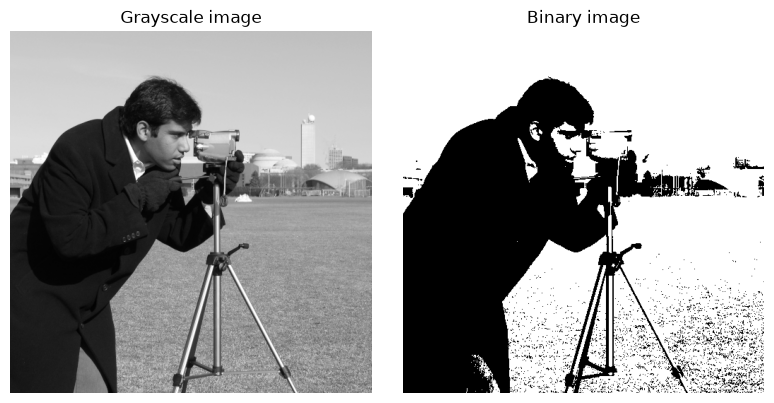

In [3]:
# Binary version of the same image (threshold = mean), values 0 / 1
binary = (img >= img.mean()).astype(np.uint8)
show([img, binary], ['Grayscale image', 'Binary image'])

## Part 1 — Border / padding

A new image of size $(H + 2w) \times (W + 2w)$ is filled with the border colour and the original image is copied into the centre.

In [4]:
def add_border(image, width, color):
    """Pad `image` with a border of `width` pixels filled with `color`."""
    h, w = image.shape[:2]
    out = np.empty((h + 2 * width, w + 2 * width) + image.shape[2:], dtype=image.dtype)
    out[...] = color                                  # fill everything with the border colour
    out[width:width + h, width:width + w] = image     # copy the original into the centre
    return out

### Grayscale image

Enter border width in pixels (grayscale image): no valid input, using default = 30
Enter border intensity 0 (black) - 255 (white): no valid input, using default = 128
Original size: (512, 512) -> with border: (572, 572)


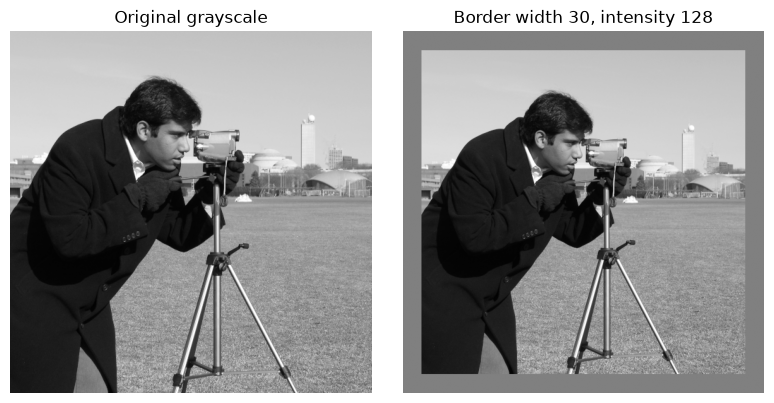

In [5]:
bw = ask("Enter border width in pixels (grayscale image)", 30, int)
bc = ask("Enter border intensity 0 (black) - 255 (white)", 128, int)
bc = int(np.clip(bc, 0, 255))

gray_bordered = add_border(img, bw, bc)
print("Original size:", img.shape, "-> with border:", gray_bordered.shape)
show([img, gray_bordered], ['Original grayscale', f'Border width {bw}, intensity {bc}'])

### Binary image
For a binary image the border colour can only be 0 (black) or 1 (white).

Enter border width in pixels (binary image): no valid input, using default = 30
Enter border colour: 0 = black, 1 = white: no valid input, using default = 1


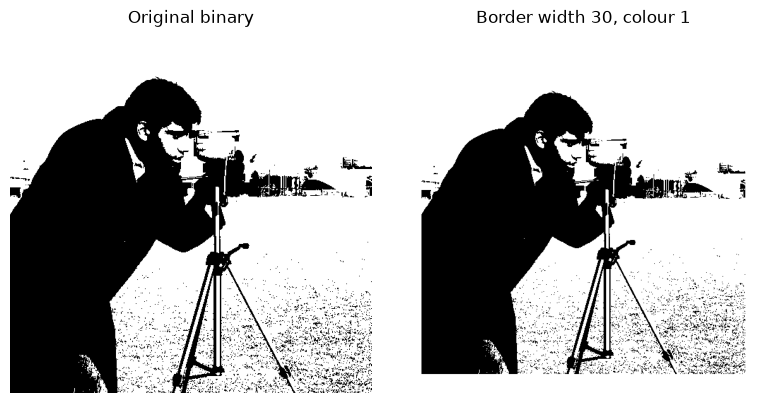

In [6]:
bw_bin = ask("Enter border width in pixels (binary image)", 30, int)
bc_bin = ask("Enter border colour: 0 = black, 1 = white", 1, int)
bc_bin = 1 if bc_bin else 0

binary_bordered = add_border(binary, bw_bin, bc_bin)
show([binary, binary_bordered], ['Original binary', f'Border width {bw_bin}, colour {bc_bin}'])

### Extra — colour border on an RGB image

Enter border colour as R,G,B: no valid input, using default = (255, 0, 0)


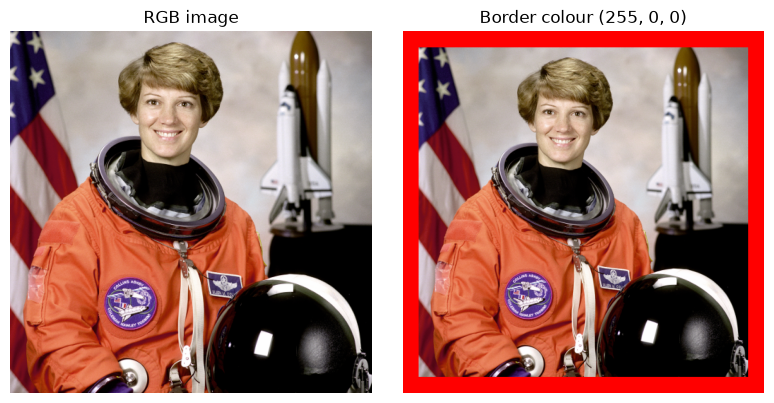

In [7]:
rgb = data.astronaut()
color = ask("Enter border colour as R,G,B", (255, 0, 0), lambda s: tuple(int(v) for v in s.split(',')))
show([rgb, add_border(rgb, 25, color)], ['RGB image', f'Border colour {color}'])

## Part 2 — Image complement (negative)

- Grayscale (L = 256 levels): $\; s = (L - 1) - r = 255 - r$
- Binary: $\; s = 1 - r$ (black and white are swapped)

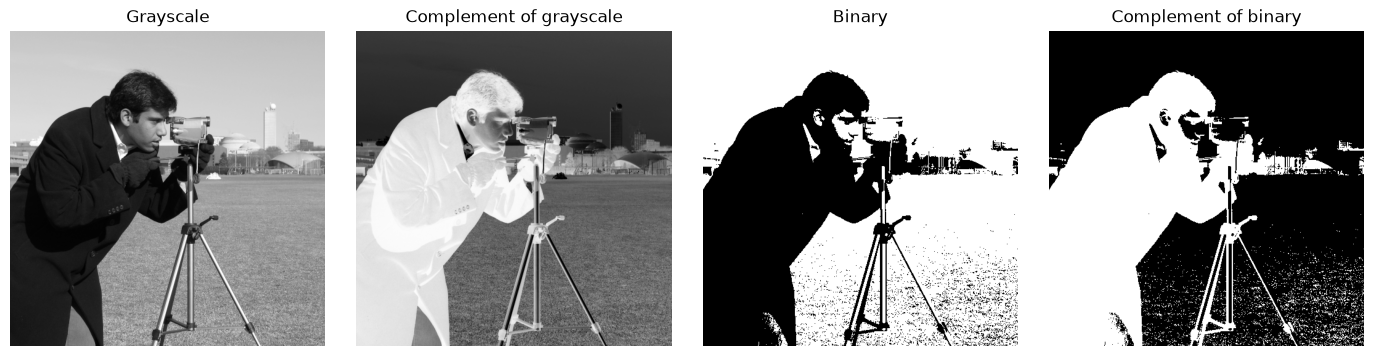

Complement twice == original (gray): True
Complement twice == original (binary): True


In [8]:
def complement_gray(image, L=256):
    return ((L - 1) - image.astype(np.int32)).astype(np.uint8)

def complement_binary(image):
    return (1 - image).astype(np.uint8)

gray_neg = complement_gray(img)
bin_neg = complement_binary(binary)

show([img, gray_neg, binary, bin_neg],
     ['Grayscale', 'Complement of grayscale', 'Binary', 'Complement of binary'], cols=4, size=3.5)

# sanity check: complementing twice gives the original back
print("Complement twice == original (gray):", np.array_equal(complement_gray(gray_neg), img))
print("Complement twice == original (binary):", np.array_equal(complement_binary(bin_neg), binary))

**Observation:** The complement turns dark regions bright and bright regions dark, which makes detail in dark areas easier to see. Doing it twice gives back the original image.